# Sedap or Overhyped? English–Malay Code-Switching and Sentiment in Ayam Gepuk Reviews.

## Install package

In [3]:
%pip install pandas openpyxl matplotlib

  Using cached openpyxl-3.1.5-py2.py3-none-any.whl.metadata (2.5 kB)
  Using cached matplotlib-3.11.2-cp313-cp313-win_amd64.whl.metadata (80 kB)
  Using cached contourpy-1.4.0-cp313-cp313-win_amd64.whl.metadata (3.8 kB)
Using cached openpyxl-3.1.5-py2.py3-none-any.whl (250 kB)
Using cached matplotlib-3.11.2-cp313-cp313-win_amd64.whl (9.3 MB)
Using cached contourpy-1.4.0-cp313-cp313-win_amd64.whl (234 kB)

   ---------------------------------------- 0/3 [openpyxl]
   ---------------------------------------- 0/3 [openpyxl]
   ---------------------------------------- 0/3 [openpyxl]
   ---------------------------------------- 0/3 [openpyxl]
   ---------------------------------------- 0/3 [openpyxl]
   ---------------------------------------- 0/3 [openpyxl]
   ---------------------------------------- 0/3 [openpyxl]
   ---------------------------------------- 0/3 [openpyxl]
   ---------------------------------------- 0/3 [openpyxl]
   ---------------------------------------- 0/3 [openpyxl]
 

## Import packages and define path

In [4]:
from pathlib import Path
from collections import Counter
import re

import pandas as pd
import matplotlib.pyplot as plt

# Assumes the notebook runs from the notebooks folder.
PROJECT_DIR = Path.cwd().parent
INPUT_FILE = PROJECT_DIR / "Data" / "CPC 353 Dataset.xlsx"

TABLE_DIR = PROJECT_DIR / "Outputs" / "Tables"
FIGURE_DIR = PROJECT_DIR / "Outputs" / "Figures"

TABLE_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

assert INPUT_FILE.exists(), f"File not found: {INPUT_FILE}"

## Load the annotated dataset

In [34]:
df = pd.read_excel(
    INPUT_FILE,
    sheet_name="Self-Collected Data",
    header=3,
    usecols="A:M",
    dtype={"Review ID": "string"},
    keep_default_na=False,
)

# Track original sheet rows before selecting populated records.
df.insert(0, "source_row", range(5, len(df) + 5))

# Ignore unused worksheet rows, while preserving all populated records.
data_columns = df.drop(columns="source_row")

populated = data_columns.apply(
    lambda column: (
        column.notna()
        & column.astype("string").str.strip().ne("").fillna(False)
    )
).any(axis=1)


df = df.loc[populated].copy()

df.head()

,source_row,Review ID,Data Origin,Product Category,Restaurant Location,Source Platform,Source URL,Rating (1-5),Review Date,Review Text,Language Classification,Code-Switching Type,Notes / Annotator Comments,Sentiment
0,5,REV-001,Self-Collected (Real),Ayam Gepuk,Ayam Gepuk Macet Chow Kit,Google Reviews,https://maps.app.goo.gl/BohQVGqPMgvuPLD57?g_st=aw,5,2026-05-28,Best ayam gepuk in Chow Kit area. Large portio...,Code-switched,Intra-sentential,"“Large portion dan sedap"" and ""Sambal also cuk...",Positive
1,6,REV-002,Self-Collected (Real),Ayam Gepuk,Ayam Gepuk Macet Chow Kit,Google Reviews,https://maps.app.goo.gl/BohQVGqPMgvuPLD57?g_st=aw,5,2026-02-04,Dont know where to eat and just google so we f...,Code-switched,Intra-sentential,"""The Kobis Goreng alsoo sedap!"" combines Engli...",Positive
2,7,REV-003,Self-Collected (Real),Ayam Gepuk,Ayam Gepuk Macet Chow Kit,Google Reviews,https://maps.app.goo.gl/BohQVGqPMgvuPLD57?g_st=aw,5,2025-11-26,I’m not the type who usually will leave a revi...,Code-switched,Intra-sentential,"""they will come to your table & bawa your plat...",Positive
3,8,REV-004,Self-Collected (Real),Ayam Gepuk,Ayam Gepuk Macet Chow Kit,Google Reviews,https://maps.app.goo.gl/BohQVGqPMgvuPLD57?g_st=aw,5,2026-05-18,Finally found ayam gepuk that really makes me ...,Code-switched,Intra-sentential,"“Ayam sedap, sambals the best, but paling best...",Positive
4,9,REV-005,Self-Collected (Real),Ayam Gepuk,Ayam Gepuk Macet Chow Kit,Google Reviews,https://maps.app.goo.gl/BohQVGqPMgvuPLD57?g_st=aw,5,2025-08-23,"Service bagus, portion besar and value for mon...",Code-switched,Intra-sentential,"“Service bagus, portion besar and value for mo...",Positive


In [7]:
# Confirmed expected columns exist

required_columns = [
    "Review ID",
    "Restaurant Location",
    "Review Text",
    "Language Classification",
    "Code-Switching Type",
    "Notes / Annotator Comments",
    "Sentiment",
]

missing_columns = set(required_columns) - set(df.columns)

assert not missing_columns, (
    f"Missing expected columns: {sorted(missing_columns)}"
)

## Check data quality

In [8]:
issues = []

for column in required_columns:
    blank = (df[column].isna() | df[column].astype("string").str.strip().eq("").fillna(False))

    for _, row in df.loc[blank].iterrows():
        issues.append({
            "source_row": row["source_row"],
            "review_id": row["Review ID"],
            "field": column,
            "issue": "Missing or empty value",
        })

for column in ["Review ID", "Review Text"]:
    duplicated = df[column].notna() & df[column].duplicated(keep=False)

    for _, row in df.loc[duplicated].iterrows():
        issues.append({
            "source_row": row["source_row"],
            "review_id": row["Review ID"],
            "field": column,
            "issue": "Exact duplicate; review before taking action",
        })

issue_log = pd.DataFrame(
    issues,
    columns=["source_row", "review_id", "field", "issue"],
)

issue_log.to_csv(
    TABLE_DIR / "data_review_flags.csv",
    index=False,
    encoding="utf-8-sig",
)

issue_log

,source_row,review_id,field,issue
0,16,REV-012,Code-Switching Type,Missing or empty value
1,32,REV-028,Code-Switching Type,Missing or empty value
2,41,REV-037,Code-Switching Type,Missing or empty value
3,43,REV-039,Code-Switching Type,Missing or empty value
4,44,REV-040,Code-Switching Type,Missing or empty value
5,45,REV-041,Code-Switching Type,Missing or empty value
6,46,REV-042,Code-Switching Type,Missing or empty value
7,48,REV-044,Code-Switching Type,Missing or empty value
8,50,REV-046,Code-Switching Type,Missing or empty value
9,53,REV-049,Code-Switching Type,Missing or empty value


In [15]:
# Display the actual count
print("Total reviews:", len(df), "\n")
print(df["Language Classification"].value_counts(dropna=False), "\n")
print(df["Code-Switching Type"].value_counts(dropna=False))

Total reviews: 197 

Language Classification
Code-switched    144
English           36
Malay             17
Name: count, dtype: int64 

Code-Switching Type
Intra-sentential    139
NaN                  53
Inter-sentential      5
Name: count, dtype: int64


## Analysis subset and distribution table

In [21]:
cs = df.loc[df["Language Classification"].eq("Code-switched")].copy()

assert len(cs) > 0, "No code-switched reviews were found."

# Analysis for language type
language_summary = (
    df["Language Classification"]
    .value_counts()
    .rename_axis("language")
    .reset_index(name="review_count")
)

language_summary["percentage"] = (language_summary["review_count"] / len(df) * 100).round(2)

# Analysis for code-switching type
switching_summary = (
    cs["Code-Switching Type"]
    .value_counts()
    .reindex(
        ["Intra-sentential", "Inter-sentential", "Tag Switching"],
        fill_value=0,
    )
    .rename_axis("primary_switching_type")
    .reset_index(name="review_count")
)

switching_summary["percentage"] = (switching_summary["review_count"] / len(cs) * 100).round(2)

display(language_summary)
display(switching_summary)

,language,review_count,percentage
0,Code-switched,144,73.10
1,English,36,18.27
2,Malay,17,8.63


,primary_switching_type,review_count,percentage
0,Intra-sentential,139,96.53
1,Inter-sentential,5,3.47
2,Tag Switching,0,0.00


## Define the search terms

In [22]:
search_terms = {
    "sedap": ["sedap", "sedapp", "sedappp", "sedapppppp"],
    "pedas": ["pedas"],
    "service": ["service"],
    "tapi": ["tapi"],
    "but": ["but"],
    "repeat": ["repeat"],
    "portion": ["portion"],
    "refill": ["refill"],
    "juicy": ["juicy"],
    "worth": ["worth"],
}

In [23]:
search_register = pd.DataFrame([
    {
        "search_term": term,
        "included_forms": ", ".join(forms),
        "case_sensitive": False,
        "context_words_each_side": 5,
    }
    for term, forms in search_terms.items()
])

search_register

,search_term,included_forms,case_sensitive,context_words_each_side
0,sedap,"sedap, sedapp, sedappp, sedapppppp",False,5
1,pedas,pedas,False,5
2,service,service,False,5
3,tapi,tapi,False,5
4,but,but,False,5
5,repeat,repeat,False,5
6,portion,portion,False,5
7,refill,refill,False,5
8,juicy,juicy,False,5
9,worth,worth,False,5


## Keyword in Context (KWIC) implementation

In [24]:
# KWIC function
def extract_kwic(text, pattern, window=5):
    """Return source-preserving context for each regex match."""
    tokens = list(re.finditer(r"\S+", text))

    for match in pattern.finditer(text):
        overlapping = [
            i for i, token in enumerate(tokens)
            if token.start() < match.end()
            and token.end() > match.start()
        ]

        if not overlapping:
            continue

        first_token = overlapping[0]
        last_token = overlapping[-1]

        left_index = max(0, first_token - window)
        right_index = min(len(tokens) - 1, last_token + window)

        context_start = tokens[left_index].start()
        context_end = tokens[right_index].end()

        yield {
            "match_start": match.start(),
            "match_end": match.end(),
            "left_context": text[context_start:match.start()],
            "matched_form": match.group(),
            "right_context": text[match.end():context_end],
        }

In [26]:
# Result of KWIC
kwic_rows = []

for _, review in cs.iterrows():
    text = review["Review Text"]

    if not isinstance(text, str) or not text.strip():
        continue

    for term, forms in search_terms.items():
        alternatives = "|".join(
            re.escape(form)
            for form in sorted(set(forms), key=len, reverse=True)
        )

        pattern = re.compile(
            rf"(?<!\w)(?:{alternatives})(?!\w)",
            flags=re.IGNORECASE,
        )

        for occurrence in extract_kwic(text, pattern):
            kwic_rows.append({
                "review_id": review["Review ID"],
                "source_row": review["source_row"],
                "search_term": term,
                **occurrence,
                "primary_switching_type":
                    review["Code-Switching Type"],
                "restaurant": review["Restaurant Location"],
                "sentiment": review["Sentiment"],
                "existing_notes":
                    review["Notes / Annotator Comments"],
                "full_review": text,
            })

kwic = pd.DataFrame(kwic_rows)

kwic.insert(
    0,
    "hit_id",
    [
        f"{row.review_id}:{row.search_term}:{row.match_start}"
        for row in kwic.itertuples()
    ],
)

kwic.head(10)

,hit_id,review_id,source_row,search_term,match_start,match_end,left_context,matched_form,right_context,primary_switching_type,restaurant,sentiment,existing_notes,full_review
0,REV-001:sedap:52,REV-001,5,sedap,52,57,Kit area. Large portion dan,sedap,. Sambal also cukup pedas. Kobis,Intra-sentential,Ayam Gepuk Macet Chow Kit,Positive,"“Large portion dan sedap"" and ""Sambal also cuk...",Best ayam gepuk in Chow Kit area. Large portio...
1,REV-001:pedas:77,REV-001,5,pedas,77,82,dan sedap. Sambal also cukup,pedas,". Kobis goreng, tempe etc also",Intra-sentential,Ayam Gepuk Macet Chow Kit,Positive,"“Large portion dan sedap"" and ""Sambal also cuk...",Best ayam gepuk in Chow Kit area. Large portio...
2,REV-001:portion:40,REV-001,5,portion,40,47,in Chow Kit area. Large,portion,dan sedap. Sambal also cukup,Intra-sentential,Ayam Gepuk Macet Chow Kit,Positive,"“Large portion dan sedap"" and ""Sambal also cuk...",Best ayam gepuk in Chow Kit area. Large portio...
3,REV-002:sedap:903,REV-002,6,sedap,903,908,restaurant. The Kobis Goreng alsoo,sedap,"! Not bitter at all, still",Intra-sentential,Ayam Gepuk Macet Chow Kit,Positive,"""The Kobis Goreng alsoo sedap!"" combines Engli...",Dont know where to eat and just google so we f...
4,REV-002:but:618,REV-002,6,but,618,621,"itself to topup our food,",but,here the staff always by,Intra-sentential,Ayam Gepuk Macet Chow Kit,Positive,"""The Kobis Goreng alsoo sedap!"" combines Engli...",Dont know where to eat and just google so we f...
5,REV-002:repeat:974,REV-002,6,repeat,974,980,taste the sweetness. Will alwaysss,repeat,again and again heree!! Thank,Intra-sentential,Ayam Gepuk Macet Chow Kit,Positive,"""The Kobis Goreng alsoo sedap!"" combines Engli...",Dont know where to eat and just google so we f...
6,REV-002:portion:699,REV-002,6,portion,699,706,food here also very HUGE,PORTION,! Sambal very good &,Intra-sentential,Ayam Gepuk Macet Chow Kit,Positive,"""The Kobis Goreng alsoo sedap!"" combines Engli...",Dont know where to eat and just google so we f...
7,REV-002:refill:479,REV-002,6,refill,479,485,Kacang & Nasi is free,refill,which is we just call,Intra-sentential,Ayam Gepuk Macet Chow Kit,Positive,"""The Kobis Goreng alsoo sedap!"" combines Engli...",Dont know where to eat and just google so we f...
8,REV-002:refill:532,REV-002,6,refill,532,538,the staff and they will,refill,that for you !! Others,Intra-sentential,Ayam Gepuk Macet Chow Kit,Positive,"""The Kobis Goreng alsoo sedap!"" combines Engli...",Dont know where to eat and just google so we f...
9,REV-002:juicy:830,REV-002,6,juicy,830,835,"goes to the chicken, very",juicy,and big size compared to,Intra-sentential,Ayam Gepuk Macet Chow Kit,Positive,"""The Kobis Goreng alsoo sedap!"" combines Engli...",Dont know where to eat and just google so we f...


In [32]:
if df["Review ID"].duplicated().any():
    raise ValueError(
        "Duplicate review IDs must be reviewed before passage annotation."
    )

review_lookup = df.set_index("Review ID")

def show_review(review_id):
    """Display original text and labels for manual inspection."""
    if review_id not in review_lookup.index:
        raise KeyError(f"Unknown review ID: {review_id}")

    row = review_lookup.loc[review_id]

    print("Review:", review_id)
    print("Source row:", row["source_row"])
    print("Primary switching label:", row["Code-Switching Type"])
    print("Sentiment:", row["Sentiment"])
    print("\nORIGINAL TEXT:\n")
    print(row["Review Text"])
    print("\nEXISTING NOTES:\n")
    print(row["Notes / Annotator Comments"])

# Example inspection:
show_review("REV-001")

Review: REV-001
Source row: 5
Primary switching label: Intra-sentential
Sentiment: Positive

ORIGINAL TEXT:

Best ayam gepuk in Chow Kit area. Large portion dan sedap. Sambal also cukup pedas. Kobis goreng, tempe etc also very well made. Located close to Quill City Mall, and the shop is also air conditioned. I usually come here for dinner.

EXISTING NOTES:

“Large portion dan sedap" and "Sambal also cukup pedas." combines English and Malay within one sentence. The reviewer positively evaluates portion size and taste.”


## Verify and summarise extracted hits

In [27]:
assert kwic["hit_id"].is_unique

for row in kwic.itertuples():
    assert (
        row.full_review[row.match_start:row.match_end]
        == row.matched_form
    )

keyword_summary = (
    kwic.groupby("search_term")
    .agg(
        occurrences=("hit_id", "size"),
        distinct_reviews=("review_id", "nunique"),
    )
    .sort_values("distinct_reviews", ascending=False)
    .reset_index()
)

display(keyword_summary)

,search_term,occurrences,distinct_reviews
0,sedap,104,79
1,service,49,39
2,tapi,52,36
3,pedas,50,31
4,but,52,29
5,repeat,19,18
6,portion,15,12
7,refill,15,11
8,juicy,11,9
9,worth,6,6


## Create a separate interpretation spreadsheet

In [ ]:
# Create a new separate spreadsheet
review_sheet = kwic.copy()

interpretation_columns = [
    "evidence_status",
    "english_span",
    "malay_span",
    "observed_switch_type",
    "pattern_group",
    "contextual_function",
    "food_name_only",
    "analysis_notes",
]

for column in interpretation_columns:
    review_sheet[column] = ""

review_sheet.to_excel(
    TABLE_DIR / "kwic_for_interpretation.xlsx",
    index=False,
)

## Analyse inter-sentential cases

In [29]:
inter_reviews = cs.loc[
    cs["Code-Switching Type"].eq("Inter-sentential"),
    [
        "Review ID",
        "source_row",
        "Review Text",
        "Notes / Annotator Comments",
        "Sentiment",
    ],
].copy()

display(inter_reviews)

,Review ID,source_row,Review Text,Notes / Annotator Comments,Sentiment
5,REV-006,10,sedapppppp gileeeeee‼️ saya tiap minggu dengn ...,“memang sedap ah‼️🤤 confirm repeat’ switches f...,Positive
15,REV-016,20,Ayam gepuk yang lazat\nServices tip top\nSis p...,"""Ayam gepuk yang lazat"" to ""Services tip top"" ...",Positive
53,REV-054,58,sedap！！recommend,"""sedap！！recommend"" switches from a Malay evalu...",Positive
129,REV-130,134,SEDAP GILA!!! Must try ok? All the way from sg...,"""SEDAP GILA!!! Must try ok?"" switches from a M...",Positive
131,REV-132,136,Taste very delicious. Sangat sedap,"""Taste very delicious. Sangat sedap"" switches ...",Positive


In [30]:
# Produce final tables
language_summary.to_csv(TABLE_DIR / "language_distribution.csv", index=False)

switching_summary.to_csv(TABLE_DIR / "primary_switching_distribution.csv", index=False)

search_register.to_csv(TABLE_DIR / "search_register.csv", index=False)

keyword_summary.to_csv(TABLE_DIR / "keyword_search_summary.csv", index=False)

kwic.to_csv(TABLE_DIR / "kwic_all_hits.csv", index=False, encoding="utf-8-sig",)

inter_reviews.to_excel(TABLE_DIR / "inter_sentential_cases.xlsx", index=False,)

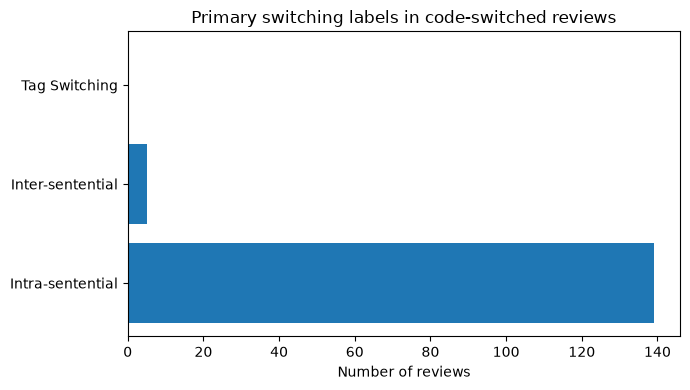

In [31]:
# Produce final figures
fig, ax = plt.subplots(figsize=(7, 4))

ax.barh(
    switching_summary["primary_switching_type"],
    switching_summary["review_count"],
)

ax.set_xlabel("Number of reviews")
ax.set_title("Primary switching labels in code-switched reviews")

fig.tight_layout()
fig.savefig(
    FIGURE_DIR / "primary_switching_distribution.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()